In [1]:
import os, sys
if 'HOME' in os.environ.keys():
    sys.path.append(os.environ['HOME']+'/Software/pyerre/framework')
    sys.path.append(os.environ['HOME']+'/Software/pyerre/proc_functions')
else:
    sys.path.append('C:/Software/pyerre/framework')
    sys.path.append('C:/Software/pyerre/proc_functions')
os.environ['DISPLAY'] = 'localhost:10.0'
sys.path.append('/usr/lib/python3/dist-packages')
sys.path.append(r'C:\Software\pyqni\framework')

In [2]:
from magic_selectors import select_basedir, select_directory, \
    select_filesave_fits, select_fileopen_fits, select_roi, \
    select_multiple_rois

from mergers import *

from img_utils import * # import image utilities

from processors import test_proc, batch_proc, single_proc
from parameters import set_general_scope, set_group_scope, set_params, param

from PyQNI import *
from bb import *
from sbkg import * 

import matplotlib
import matplotlib.pyplot as plt
#import scipy.signal as sp
import numpy as np
from natsort import natsorted

%matplotlib inline
font = {'family' : 'DejaVu Sans',
        'weight' : 'normal',
        'size'   : 12}

In [3]:
src_dir = r'M:\90_projects\93_data\P20240948\temp3\final'

In [4]:
file_list = os.listdir(src_dir)
file_list = natsorted(file_list)

r0 = 800
x0 = 200+r0
y0 = 400+r0
conv_thickness = 3.6
pixel_size = 0.011    # unit mm

img_series = []
thickness_series = []
avg_series = np.array([])

for i in range(len(file_list)):
    img = get_img(os.path.join(src_dir, file_list[i]))
    img = img[y0-r0:y0+r0, x0-r0:x0+r0]
    img_series.append(img)

    y, x = np.ogrid[:img.shape[0], :img.shape[1]]
    distance = np.sqrt((x - r0)**2 + (y - r0)**2)
    circle_mask = (distance <= r0)

    thickness_img = img / conv_thickness
    thickness_series.append(thickness_img)

    avg_thickness = np.mean(thickness_img[circle_mask])
    avg_series = np.append(avg_series, avg_thickness)

# img_series = img_series[1:-1]
# thickness_series = thickness_series[1:-1]
# avg_series = avg_series[1:-1]

# avg_series = avg_series - avg_series[0]

print(avg_series)


[0.40958413 0.2103873  0.67488247 0.16040114]


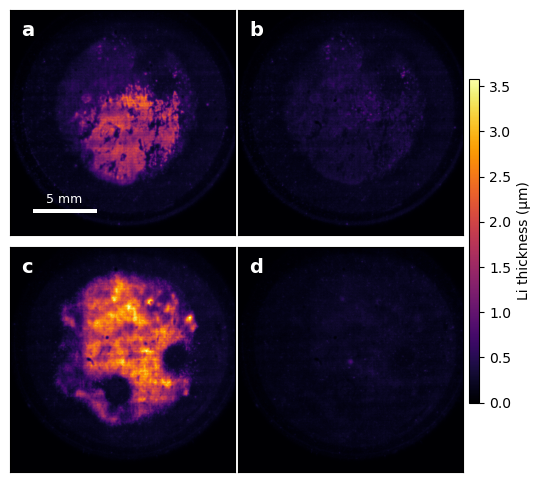

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np


x_min, x_max = 0, 2*r0*pixel_size 
y_min, y_max = 0, 2*r0*pixel_size
img_to_show = [0,1,2,3]  # Your selected images

# Get reference image min/max (index 17)
ref_img = thickness_series[0]
vmin, vmax = ref_img.min(), ref_img.max()

# Create 2x3 grid with tight spacing
fig, axes = plt.subplots(2, 2, figsize=(7, 6),  # Reduced height
                        gridspec_kw={'wspace': 0, 'hspace': 0.05})  # Tighter spacing

# Flatten axes for easy iteration
axes = axes.ravel()

for j, img_idx in enumerate(img_to_show):
    ax = axes[j]
    
    # Display image
    im = ax.imshow(thickness_series[img_idx],
                  cmap='inferno',
                  extent=[x_min, x_max, y_min, y_max],
                  origin='lower',
                  vmin=vmin,
                  vmax=vmax)
    
    # Remove ticks and labels
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    
    # Add letter label (a-f)
    letter = chr(97 + j)  # 97 = 'a'
    ax.text(0.05, 0.95, letter,  # Moved slightly lower
           transform=ax.transAxes,
           fontsize=14,  # Slightly smaller
           fontweight='bold',
           color='white', ha='left', va='top')
    
    # Add scale bar to first subplot (a)
    if j == 0:
        scale_length = 5  # mm
        scale_x_start = 0.1 * x_max
        scale_y_pos = 0.1 * y_max
        
        ax.add_patch(patches.Rectangle(
            (scale_x_start, scale_y_pos),
            scale_length,
            0.015 * y_max,  # Thinner bar
            facecolor='white',
            edgecolor='none'
        ))
        
        ax.text(scale_x_start + scale_length/2,
               scale_y_pos + 0.03 * y_max,  # Moved closer
               '5 mm',
               color='white',
               ha='center', va='bottom',
               fontsize=9)  # Smaller font

# Add single colorbar (adjusted position)
cbar = fig.colorbar(im, ax=axes.tolist(), 
                   shrink=0.7, pad=0.01, aspect=30)  # More compact
cbar.set_label('Li thickness (μm)', fontsize=10)  # Smaller font

# plt.tight_layout(pad=0.5)  # Reduced padding
# plt.savefig('12mm/Operando_Li_thickness_2x3_12mm.png', dpi=300, bbox_inches='tight')
# plt.show()

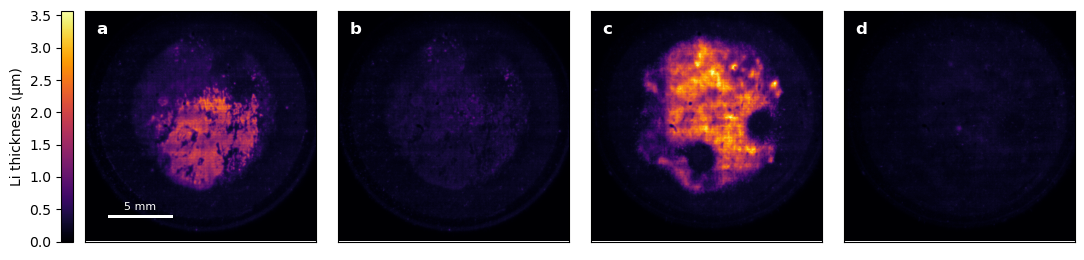

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Assuming r0, pixel_size, and thickness_series are defined
x_min, x_max = 0, 2 * r0 * pixel_size
y_min, y_max = 0, 2 * r0 * pixel_size
img_to_show = [0,1,2,3]

# Get consistent color scale from reference image
ref_img = thickness_series[0]
vmin, vmax = ref_img.min(), ref_img.max()

# Create figure with 1 row and 6 image slots
fig = plt.figure(figsize=(13, 3))
gs = fig.add_gridspec(1, 4, wspace=0.02)  # Only image slots here

# Image axes
axes = [fig.add_subplot(gs[0, i]) for i in range(4)]

for j, img_idx in enumerate(img_to_show):
    ax = axes[j]
    
    im = ax.imshow(thickness_series[img_idx],
                   cmap='inferno',
                   extent=[x_min, x_max, y_min, y_max],
                   origin='lower',
                   vmin=vmin, vmax=vmax)
    
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Letter label (a-f)
    letter = chr(97 + j)
    ax.text(0.05, 0.95, letter,
            transform=ax.transAxes,
            fontsize=12, fontweight='bold',
            color='white', ha='left', va='top')
    
    # Scale bar on first image
    if j == 0:
        scale_length = 5  # mm
        scale_x_start = 0.1 * x_max
        scale_y_pos = 0.1 * y_max
        
        ax.add_patch(patches.Rectangle(
            (scale_x_start, scale_y_pos),
            scale_length,
            0.015 * y_max,
            facecolor='white',
            edgecolor='none'
        ))
        
        ax.text(scale_x_start + scale_length / 2,
                scale_y_pos + 0.03 * y_max,
                '5 mm',
                color='white',
                ha='center', va='bottom',
                fontsize=8)

# Add a small inset colorbar to the left of the first image
inset_ax = inset_axes(
    axes[0],             # anchor to the first image
    width="5%",          # width as percentage of image width
    height="100%",       # same height as image
    loc='center left',
    bbox_to_anchor=(-0.1, 0, 1, 1),  # (x0, y0, width, height)
    bbox_transform=axes[0].transAxes,
    borderpad=0
)

cbar = fig.colorbar(im, cax=inset_ax)
cbar.set_label('Li thickness (μm)', fontsize=10)
cbar.ax.yaxis.set_ticks_position('left')
cbar.ax.yaxis.set_label_position('left')


# Save and display
plt.savefig('12mm/Operando_Li_thickness_1x6_12mm.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
time_points = np.array([0.0, 5.41326078, 10.81393347, 16.22005, 21.62236735,
        27.02062161, 32.42415056, 37.82622002, 43.22664154, 48.62777148,
        54.02995987, 59.43024724, 64.83295335, 70.24511701, 75.64753496,
        81.0587863, 86.48243297, 91.89206529, 97.3158393, 102.71930678,
        108.13917647, 113.58682422, 118.99537876, 124.41292557, 129.8267374,
        135.24405539, 140.66107508, 146.07429953, 151.48573402, 156.89363104,
        162.29563948, 167.70408183, 173.10945531, 178.51008661, 183.91531179,
        189.32456393, 194.73887024, 200.15770938, 205.57325095, 210.98788373,
        216.40183671, 220.50765092])

time_points = time_points[1:-1]
time_points = time_points - time_points[0]

In [ ]:
print(time_points)

In [ ]:
img_start_time = '11/07/2024 04:55:06'      # read from neutron data, manually convert format to american
stripping_start_time = '11/07/2024 06:29:03'    # read from potentiostat data, -1 from index
stripping_end_time = '11/07/2024 07:28:23'    # read from potentiostat data, +1 to index
plating2_start_time = '11/07/2024 07:58:41'    # read from potentiostat data, -1 from index

In [ ]:
potentio_path = r'M:\90_projects\93_data\P20240948\1107_C01.txt'

In [ ]:
potentio = pd.read_csv(potentio_path, sep='\t', engine='python')
potentio['time/s'] = potentio['time/s'].str.split('.').str[0]
potentio = potentio.drop(columns=['Unnamed: 6'])

In [ ]:
start_index = potentio[potentio.iloc[:, 0] == img_start_time].index[0]

In [ ]:
potentio_times =  potentio.iloc[start_index:, 0].to_numpy()
potentio_times_raw = potentio_times
print(potentio_times_raw)
potentio_times = pd.to_datetime(potentio_times, format='%d/%m/%Y %H:%M:%S').to_numpy()

time_deltas = potentio_times - potentio_times[0]
potentio_times = time_deltas / np.timedelta64(1, 'm')

In [ ]:
stripping_start_index = potentio[potentio.iloc[:, 0] == stripping_start_time].index[0] - 1 - start_index
stripping_end_index = potentio[potentio.iloc[:, 0] == stripping_end_time].index[0] + 1 - start_index
plating2_start_index = potentio[potentio.iloc[:, 0] == plating2_start_time].index[0] - 1 - start_index
print(start_index)
print(stripping_start_index)
print(stripping_end_index)
print(plating2_start_index)

In [ ]:
capacity = potentio.iloc[start_index:, 4].to_numpy()
potentio_thicknesses =  3.9 *capacity / np.max(capacity)


In [ ]:
potentio_thicknesses[stripping_start_index:stripping_end_index+1] = potentio_thicknesses[stripping_start_index-1] - potentio_thicknesses[stripping_start_index:stripping_end_index+1]

potentio_thicknesses[stripping_end_index+1:plating2_start_index] = potentio_thicknesses[stripping_end_index]
potentio_thicknesses[plating2_start_index:] = potentio_thicknesses[plating2_start_index:] + potentio_thicknesses[plating2_start_index-1]

In [ ]:

ratio = avg_series[17] * (1+1/20) / np.max(potentio_thicknesses) 
print(ratio)
avg_series_normalized = avg_series / ratio

In [ ]:
# Create figure (6x4 inches)
plt.figure(figsize=(6, 4))

# --- Plot the high-resolution potentiometry data (3845 points) ---
plt.plot(potentio_times, potentio_thicknesses,
         color='green',       # Choose a distinct color
         alpha=0.5,         # Semi-transparent to avoid overpowering
         linewidth=2,       # Thin line
         label='Electrochemical data',
         zorder=0)         # Send to very back

# --- Plot neutron data (40 points) ---
plt.plot(time_points, avg_series, 
         'o',                     # Only dots, no line
         color='black',           # Dot color
         markerfacecolor='black', # Dot fill color
         markeredgecolor='black', # Dot edge color
         markersize=4,            # Dot size
         linestyle='none',        # No connecting line
         zorder=1,                # Above potentiometry data
         label='Neutron imaging data')    # Add label for legend

# --- Highlight specific points in green ---
highlight_indices = img_to_show  # Using your img_to_show variable
highlight_labels = ['c', 'd', 'e', 'f', 'g', 'h']

plt.scatter(time_points[highlight_indices], avg_series[highlight_indices],
            color='black',      # Bright green
            edgecolor='black',    # Black outline
            s=20,                 # Size (slightly larger than regular points)
            zorder=2)             # Bring to foreground
   

# --- Add green labels to highlighted points ---
for idx, label in zip(highlight_indices, highlight_labels):
    plt.text(time_points[idx], avg_series[idx]+0.1,
             label,
             ha='center', va='bottom',
             fontsize=14, 
             weight='bold',
             color='black',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

# --- Customize plot ---
plt.xlabel('Time (minutes)', fontsize=10)
plt.ylabel('Average Thickness (μm)', fontsize=10)

# Format ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# --- Set axis limits ---
# Find combined min/max for both datasets
x_min = min(time_points.min(), potentio_times.min())
x_max = max(time_points.max(), potentio_times.max())
y_min = min(avg_series.min(), potentio_thicknesses.min())
y_max = max(avg_series.max(), potentio_thicknesses.max())

# Add padding (2% of range)
x_padding = 0.02 * (x_max - x_min)
y_padding = 0.02 * (y_max - y_min)

plt.xlim(x_min - x_padding, x_max + x_padding)
plt.ylim(y_min - y_padding, y_max + y_padding)

# Remove grid
plt.grid(False)

# Add letter label (a-f)
plt.text(0.05, 0.96, 'b',  # Adjusted y=0.98 to bring it closer to the title
         transform=plt.gcf().transFigure,  # Use figure coordinates
         fontsize=18,
         fontweight='bold',
         color='black',
         ha='left', va='top')  # Align left and top



# Add legend (now includes both datasets)
plt.legend(fontsize=10, loc='upper right')

plt.tight_layout()

# Save the figure
plt.savefig('12mm/Combined_avg_thickness_12mm.png',
           dpi=300,
           bbox_inches='tight',
           facecolor='w')

# Show plot
plt.show()

In [ ]:
print(avg_series)

In [ ]:
thickness_series_normalized = thickness_series / ratio

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Parameters
r0 = 546  # radius in pixels
pixel_size = 0.011  # mm/pixel
x_min, x_max = 0, 2*r0*pixel_size 
y_min, y_max = 0, 2*r0*pixel_size
img_to_show = [0, 8, 17, 24, 29, 39]  # Your selected images

# Get reference image min/max (index 18)
ref_img = thickness_series_normalized[17]
vmin, vmax = ref_img.min(), ref_img.max()

# Create 2x3 grid with tight spacing
fig, axes = plt.subplots(2, 3, figsize=(11, 6),  # Reduced height
                        gridspec_kw={'wspace': 0, 'hspace': 0.05})  # Tighter spacing

# Flatten axes for easy iteration
axes = axes.ravel()

for j, img_idx in enumerate(img_to_show):
    ax = axes[j]
    
    # Display image
    im = ax.imshow(thickness_series_normalized[img_idx],
                  cmap='inferno',
                  extent=[x_min, x_max, y_min, y_max],
                  origin='lower',
                  vmin=vmin,
                  vmax=vmax)
    
    # Remove ticks and labels
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    
    # Add letter label (a-f)
    letter = chr(99 + j)  # 97 = 'a'
    ax.text(0.05, 0.95, letter,  # Moved slightly lower
           transform=ax.transAxes,
           fontsize=14,  # Slightly smaller
           fontweight='bold',
           color='white', ha='left', va='top')
    
    # Add scale bar to first subplot (a)
    if j == 0:
        scale_length = 5  # mm
        scale_x_start = 0.1 * x_max
        scale_y_pos = 0.1 * y_max
        
        ax.add_patch(patches.Rectangle(
            (scale_x_start, scale_y_pos),
            scale_length,
            0.015 * y_max,  # Thinner bar
            facecolor='white',
            edgecolor='none'
        ))
        
        ax.text(scale_x_start + scale_length/2,
               scale_y_pos + 0.03 * y_max,  # Moved closer
               '5 mm',
               color='white',
               ha='center', va='bottom',
               fontsize=9)  # Smaller font

# Add single colorbar (adjusted position)
cbar = fig.colorbar(im, ax=axes.tolist(), 
                   shrink=0.7, pad=0.01, aspect=30)  # More compact
cbar.set_label('Li thickness (μm)', fontsize=10)  # Smaller font

# plt.tight_layout(pad=0.5)  # Reduced padding
plt.savefig('12mm normalized/Operando_Li_thickness_2x3 (normalized)_12mm.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Assuming r0, pixel_size, and thickness_series_normalized are defined
x_min, x_max = 0, 2 * r0 * pixel_size
y_min, y_max = 0, 2 * r0 * pixel_size
img_to_show = [0, 8, 17, 24, 29, 39]

# Get consistent color scale from reference image
ref_img = thickness_series_normalized[17]
vmin, vmax = ref_img.min(), ref_img.max()

# Create figure with 1 row and 6 image slots
fig = plt.figure(figsize=(13, 3))
gs = fig.add_gridspec(1, 6, wspace=0.02)  # Only image slots here

# Image axes
axes = [fig.add_subplot(gs[0, i]) for i in range(6)]

for j, img_idx in enumerate(img_to_show):
    ax = axes[j]
    
    im = ax.imshow(thickness_series_normalized[img_idx],
                   cmap='inferno',
                   extent=[x_min, x_max, y_min, y_max],
                   origin='lower',
                   vmin=vmin, vmax=vmax)
    
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Letter label (a-f)
    letter = chr(99 + j)
    ax.text(0.05, 0.95, letter,
            transform=ax.transAxes,
            fontsize=12, fontweight='bold',
            color='white', ha='left', va='top')
    
    # Scale bar on first image
    if j == 0:
        scale_length = 5  # mm
        scale_x_start = 0.1 * x_max
        scale_y_pos = 0.1 * y_max
        
        ax.add_patch(patches.Rectangle(
            (scale_x_start, scale_y_pos),
            scale_length,
            0.015 * y_max,
            facecolor='white',
            edgecolor='none'
        ))
        
        ax.text(scale_x_start + scale_length / 2,
                scale_y_pos + 0.03 * y_max,
                '5 mm',
                color='white',
                ha='center', va='bottom',
                fontsize=8)

# Add a small inset colorbar to the left of the first image
inset_ax = inset_axes(
    axes[0],             # anchor to the first image
    width="5%",          # slightly narrower
    height="120%",        # slightly shorter than image
    loc='center left',
    bbox_to_anchor=(-0.1, 0.1, 1, 0.8),  # adjusted positioning
    bbox_transform=axes[0].transAxes,
    borderpad=0
)

cbar = fig.colorbar(im, cax=inset_ax)
cbar.set_label('Li thickness (μm)', fontsize=10, labelpad=5)
cbar.ax.yaxis.set_ticks_position('left')
cbar.ax.yaxis.set_label_position('left')

# Set specific ticks at 4, 8, and 12
cbar.set_ticks([0, 4, 8, 12])
cbar.ax.tick_params(axis='y', labelsize=9, pad=2)  # adjust tick appearance

# Adjust subplot positions to make room for colorbar
plt.subplots_adjust(left=0.1)  # increase left margin if needed

# Save and display
plt.savefig('12mm normalized/Operando_Li_thickness_1x6 (normalized)_12mm.png', 
            dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Create figure (6x4 inches)
plt.figure(figsize=(6, 3))

# --- Plot the high-resolution potentiometry data (3845 points) ---
plt.plot(potentio_times, potentio_thicknesses,
         color='green',       # Choose a distinct color
         alpha=0.5,         # Semi-transparent to avoid overpowering
         linewidth=2,       # Thin line
         label='Electrochemical data',
         zorder=0)         # Send to very back

# --- Plot neutron data (40 points) ---
plt.plot(time_points, avg_series_normalized, 
         'o',                     # Only dots, no line
         color='black',           # Dot color
         markerfacecolor='black', # Dot fill color
         markeredgecolor='black', # Dot edge color
         markersize=4,            # Dot size
         linestyle='none',        # No connecting line
         zorder=1,                # Above potentiometry data
         label='Neutron imaging data')    # Add label for legend

# --- Highlight specific points in green ---
highlight_indices = img_to_show  # Using your img_to_show variable
highlight_labels = ['c', 'd', 'e', 'f', 'g', 'h']

plt.scatter(time_points[highlight_indices], avg_series_normalized[highlight_indices],
            color='black',      # Bright green
            edgecolor='black',    # Black outline
            s=20,                 # Size (slightly larger than regular points)
            zorder=2)             # Bring to foreground
   

# --- Add green labels to highlighted points ---
for idx, label in zip(highlight_indices, highlight_labels):
    plt.text(time_points[idx], avg_series_normalized[idx]+0.1,
             label,
             ha='center', va='bottom',
             fontsize=14, 
             weight='bold',
             color='black',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

# --- Customize plot ---
plt.xlabel('Time (minutes)', fontsize=10)
plt.ylabel('Average Thickness (μm)', fontsize=10)

# Format ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# --- Set axis limits ---
# Find combined min/max for both datasets
x_min = min(time_points.min(), potentio_times.min())
x_max = max(time_points.max(), potentio_times.max())
y_min = min(avg_series_normalized.min(), potentio_thicknesses.min())
y_max = max(avg_series_normalized.max(), potentio_thicknesses.max())



# Add padding (2% of range)
x_padding = 0.02 * (x_max - x_min)
y_padding = 0.02 * (y_max - y_min)

plt.xlim(x_min - x_padding, x_max + x_padding)
plt.ylim(y_min - y_padding, y_max + y_padding)

# Remove grid
plt.grid(False)

# Add letter label (a-f)
plt.text(0.05, 0.96, 'b',  # Adjusted y=0.98 to bring it closer to the title
         transform=plt.gcf().transFigure,  # Use figure coordinates
         fontsize=18,
         fontweight='bold',
         color='black',
         ha='left', va='top')  # Align left and top



# Add legend (now includes both datasets)
plt.legend(fontsize=10, loc='upper right')

plt.tight_layout()

# Save the figure
plt.savefig('12mm normalized/Combined_avg_thickness (normalized)_12mm.png',
           dpi=300,
           bbox_inches='tight',
           facecolor='w')

# Show plot
plt.show()

In [ ]:
potentio_times_raw = potentio.iloc[start_index:, 0].to_numpy()
Ewe = potentio.iloc[start_index:, 1].to_numpy()
I = potentio.iloc[start_index:, 2].to_numpy()


import csv
# Prepare data rows
max_length = max(len(time_points), len(potentio_times), len(potentio_times_raw),
               len(potentio_thicknesses), len(Ewe), len(I))
data_rows = []
for i in range(max_length):
    row = [
        time_points[i] if i < len(time_points) else "",
        avg_series[i] if i < len(avg_series) else "",
        potentio_times[i] if i < len(potentio_times) else "",          # Numeric minutes
        potentio_times_raw[i] if i < len(potentio_times_raw) else "",  # Original datetime string
        potentio_thicknesses[i] if i < len(potentio_thicknesses) else "",
        Ewe[i] if i < len(Ewe) else "",
        I[i] if i < len(I) else ""
    ]
    data_rows.append(row)

# Write to CSV
with open("output_data_2.csv", "w", newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow([
        "time_points (min)",
        "avg_series (um)",
        "potentio_times (min)",       # Numeric minutes
        "potentio_times_raw",          # Original datetime (no unit)
        "potentio_thicknesses (um)",
        "Ewe (V)",
        "I (A)"
    ])
    writer.writerows(data_rows)

print("Data saved to 'output_data_2.csv'")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x_min, x_max = 0, 2 * r0 * pixel_size  
y_min, y_max = 0, 2 * r0 * pixel_size  

# Get reference image (19th image, index 18) min/max values
ref_img = thickness_series[17]  
vmin, vmax = ref_img.min(), ref_img.max()

for i in range(len(thickness_series)):
    plt.figure(figsize=(4, 3))  
    
    plt.imshow(
        thickness_series_normalized[i],
        cmap='inferno',
        extent=[x_min, x_max, y_min, y_max],
        origin='lower',
        vmin=vmin,
        vmax=vmax
    )
    
    plt.colorbar(label='Li thickness (μm)')  
    plt.xlabel('X Position (mm)')
    plt.ylabel('Y Position (mm)')
    
    # Set x and y ticks at 0, 2, 4, 6, etc.
    step = 2  # Ticks every 2 mm
    xticks = np.arange(0, int(x_max) + 1, step)  # 0, 2, 4, 6, ...
    yticks = np.arange(0, int(y_max) + 1, step)  # 0, 2, 4, 6, ...
    
    plt.xticks(xticks)
    plt.yticks(yticks)
    
    # Save the figure
    plt.savefig(f'12mm/movie/Operando_Li_thickness_12mm_{i+1}.png', 
               dpi=300, 
               bbox_inches='tight',
               transparent=False)
    
    plt.show()
